In [15]:
#K-MODES
#Clusterización de los clientes para perfilar según la decisión de baja voluntaria
#Se usa K-modes porque las variables a analizar son de tipo categóricas

#1. Instalar paquete
!pip install kmodes openpyxl pandas numpy matplotlib


[notice] A new release of pip is available: 25.1.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
#1.1 Instalar más paquetes

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from kmodes.kmodes import KModes

In [2]:
import os

# Muestra la carpeta actual desde la que Python está ejecutando el notebook
print("Carpeta actual:")
print(os.getcwd())

# Lista los archivos disponibles en esa carpeta
print("\nArchivos disponibles:")
print(os.listdir())

Carpeta actual:
d:\Trabajo\Claro\CASO de ingreso\Códigos

Archivos disponibles:
['K-mode.ipynb', 'K-prototye.ipynb', 'EDA_NoRuc_Volun.xlsx', 'resumen_segmentos_kmodes 3).xlsx', '~$base_segmentada_kmodes.xlsx', 'base_segmentada_kmodes 3).xlsx', 'cluster 4).xlsx', 'base_segmentada_kmodes.xlsx', 'resumen_segmentos_kmodes.xlsx', '~$resumen_segmentos_kmodes.xlsx']


In [3]:
#2. Cargar base de datos y  visualizar los primeros registros

ruta = "cluster 4).xlsx"
df = pd.read_excel(ruta)
df.head()

,TIPO_BAJA,TECNOLOGIA,TIPO_DOC,CIUDAD,FECHA_ALTA,FECHA_BAJA,fecha_alta_int,fecha_baja_int,tiempo_de_vida_dias,tiempo_de_vida_meses,rango_de_vida,FORMA_PAGO,SUBSCRIBER_ID,CANAL INGRESO INTENCION,MOTIVO DE BAJA,motivo_de_baja_agrupado,ARPU,RETENIDO
0,VOLUNTARIA,GPON,CEDULA,QUITO,2022-06-30,2026-04-18,2022-06-30,2026-04-18,1388,46.266667,> 12 meses,efectivo,1000063905123,Kiosco,Viaje,viaje,16.0,NO
1,VOLUNTARIA,HFC,CEDULA,QUITO,2023-02-02,2026-02-18,2023-02-02,2026-02-18,1112,37.066667,> 12 meses,cuenta bancaria,1000199388123,Kiosco,Traslado fuera de cobertura,traslado,22.4,NO
2,VOLUNTARIA,GPON,CEDULA,GUAYAQUIL,2023-07-04,2026-02-18,2023-07-04,2026-02-18,960,32.000000,> 12 meses,cuenta bancaria,1000340228123,Kiosco,Traslado fuera de cobertura,traslado,17.0,NO
3,VOLUNTARIA,GPON,CEDULA,AMBATO,2023-08-10,2026-06-18,2023-08-10,2026-06-18,1043,34.766667,> 12 meses,efectivo,1000377179123,Kiosco,Cambio de Proveedor,cambio de proveedor,20.0,NO
4,VOLUNTARIA,GPON,CEDULA,GUAYAQUIL,2023-05-13,2026-06-02,2023-05-13,2026-06-02,1116,37.200000,> 12 meses,cuenta bancaria,1000295999123,NaN,Cambio de Proveedor,cambio de proveedor,17.0,NO


In [4]:
#2.1 Verificar nombre de columnas
df.columns

Index(['TIPO_BAJA', 'TECNOLOGIA', 'TIPO_DOC', 'CIUDAD', 'FECHA_ALTA',
       'FECHA_BAJA', 'fecha_alta_int', 'fecha_baja_int', 'tiempo_de_vida_dias',
       'tiempo_de_vida_meses', 'rango_de_vida', 'FORMA_PAGO', 'SUBSCRIBER_ID',
       'CANAL INGRESO INTENCION', 'MOTIVO DE BAJA', 'motivo_de_baja_agrupado',
       'ARPU', 'RETENIDO'],
      dtype='str')

In [5]:
# 2.2 Definir columnas relevantes para la clusterización

# Identificador del cliente
col_id = "SUBSCRIBER_ID"

# Variables categóricas que describen el perfil del cliente o del servicio
col_tec = "TECNOLOGIA"
col_vida = "rango_de_vida"
col_pago = "FORMA_PAGO"

# Variable central del análisis: motivo de baja agrupado
col_motivo = "motivo_de_baja_agrupado"

# Variables que NO formarán los clusters, pero servirán para evaluar los segmentos
col_arpu = "ARPU"

In [6]:
#2.3 Validación de columnas requeridas

# Antes de preparar la base para K-Modes, se verifica que todas las columnas necesarias estén disponibles en el archivo cargado. 
# Esta validación evita que el análisis avance con errores silenciosos o con campos mal escritos.

#Las columnas se separan según su función: `SUBSCRIBER_ID` identifica la unidad de análisis; tecnología, rango de vida y forma de pago consolidada alimentarán la segmentación; 
# ARPU quedará reservado para describir el valor económico promedio de cada grupo.

base = df[[col_id, col_tec, col_vida, col_pago, col_motivo, col_arpu]].copy()
base.head()

,SUBSCRIBER_ID,TECNOLOGIA,rango_de_vida,FORMA_PAGO,motivo_de_baja_agrupado,ARPU
0,1000063905123,GPON,> 12 meses,efectivo,viaje,16.0
1,1000199388123,HFC,> 12 meses,cuenta bancaria,traslado,22.4
2,1000340228123,GPON,> 12 meses,cuenta bancaria,traslado,17.0
3,1000377179123,GPON,> 12 meses,efectivo,cambio de proveedor,20.0
4,1000295999123,GPON,> 12 meses,cuenta bancaria,cambio de proveedor,17.0


In [7]:
#2.4 Estandarización de variables categóricas: 
#Se estandarizan las variables categóricas que serán utilizadas en la segmentación: tecnología, rango de tiempo de vida y forma de pago consolidada. 
#El objetivo es evitar que diferencias de escritura, espacios o uso de mayúsculas/minúsculas generen categorías artificialmente distintas.

# Convertimos a texto, quitamos espacios al inicio/final y pasamos todo a mayúsculas.
for col in [col_tec, col_vida, col_pago, col_motivo]:
    base[col] = (
        base[col]
        .astype(str)
        .str.strip()
        .str.upper()
    )

base.head()

,SUBSCRIBER_ID,TECNOLOGIA,rango_de_vida,FORMA_PAGO,motivo_de_baja_agrupado,ARPU
0,1000063905123,GPON,> 12 MESES,EFECTIVO,VIAJE,16.0
1,1000199388123,HFC,> 12 MESES,CUENTA BANCARIA,TRASLADO,22.4
2,1000340228123,GPON,> 12 MESES,CUENTA BANCARIA,TRASLADO,17.0
3,1000377179123,GPON,> 12 MESES,EFECTIVO,CAMBIO DE PROVEEDOR,20.0
4,1000295999123,GPON,> 12 MESES,CUENTA BANCARIA,CAMBIO DE PROVEEDOR,17.0


In [8]:
#Revisar el tamaño de la base
base.shape

(12332, 6)

In [9]:
#2.6 Revisar datos faltantes
base[[col_tec, col_vida, col_pago, col_motivo]].isna().sum()

TECNOLOGIA                 0
rango_de_vida              0
FORMA_PAGO                 0
motivo_de_baja_agrupado    0
dtype: int64

In [10]:
#2.7 Se revisan las combinaciones más frecuentes entre tecnología, rango de tiempo de vida y forma de pago consolidada. 
# Esta exploración permite identificar concentraciones naturales dentro de las bajas voluntarias antes de aplicar K-Modes.

base[[col_tec, col_vida, col_pago, col_motivo]].value_counts().head(10)

TECNOLOGIA  rango_de_vida  FORMA_PAGO       motivo_de_baja_agrupado      
GPON        > 12 MESES     EFECTIVO         VIAJE                            1544
                           CUENTA BANCARIA  VIAJE                             933
                           EFECTIVO         PROBLEMAS ECONOMICOS              912
                                            CAMBIO DE PROVEEDOR               798
                           CUENTA BANCARIA  PROBLEMAS ECONOMICOS              620
                                            CAMBIO DE PROVEEDOR               612
                                            TRASLADO                          388
                           EFECTIVO         INCONFORMIDAD CON EL PRODUCTO     343
                                            TRASLADO                          339
                                            FALLAS EN EL SERVICIO             298
Name: count, dtype: int64

In [11]:
# Revisamos los registros donde el rango de tiempo de vida aparece como "RETENIDO"
base[base[col_vida] == "RETENIDO"].head(20)

,SUBSCRIBER_ID,TECNOLOGIA,rango_de_vida,FORMA_PAGO,motivo_de_baja_agrupado,ARPU


In [12]:
#3 CREACIÓN DE K- MODES

### Preparación de la matriz categórica para K-Modes
#Se construye la matriz que será utilizada por K-Modes. 
#Esta matriz contiene únicamente las variables categóricas seleccionadas para formar los segmentos: tecnología, rango de tiempo de vida y forma de pago consolidada.

#ARPU no se incluye en esta matriz, porque no se usará para crear los clusters. Su uso será posterior, como variable descriptiva para estimar el valor económico promedio de cada segmento.
X_kmodes = base[[col_tec, col_vida, col_pago, col_motivo]].copy()

# Revisamos las primeras filas para confirmar que la matriz contiene solo categorías.
X_kmodes.head()

,TECNOLOGIA,rango_de_vida,FORMA_PAGO,motivo_de_baja_agrupado
0,GPON,> 12 MESES,EFECTIVO,VIAJE
1,HFC,> 12 MESES,CUENTA BANCARIA,TRASLADO
2,GPON,> 12 MESES,CUENTA BANCARIA,TRASLADO
3,GPON,> 12 MESES,EFECTIVO,CAMBIO DE PROVEEDOR
4,GPON,> 12 MESES,CUENTA BANCARIA,CAMBIO DE PROVEEDOR


Initialization method and algorithm are deterministic. Setting n_init to 1.
Init: initializing centroids
Init: initializing clusters
Starting iterations...
Run 1, iteration: 1/100, moves: 0, cost: 16013.0
Initialization method and algorithm are deterministic. Setting n_init to 1.
Init: initializing centroids
Init: initializing clusters
Starting iterations...
Run 1, iteration: 1/100, moves: 0, cost: 12662.0
Initialization method and algorithm are deterministic. Setting n_init to 1.
Init: initializing centroids
Init: initializing clusters
Starting iterations...
Run 1, iteration: 1/100, moves: 0, cost: 12367.0
Initialization method and algorithm are deterministic. Setting n_init to 1.
Init: initializing centroids
Init: initializing clusters
Starting iterations...
Run 1, iteration: 1/100, moves: 55, cost: 12200.0
Run 1, iteration: 2/100, moves: 77, cost: 12200.0


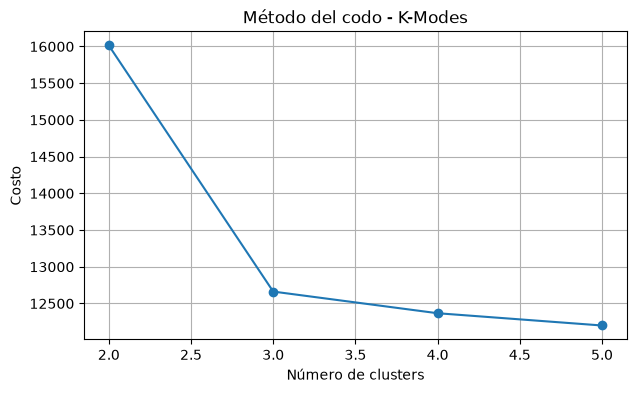

In [22]:
##3.1 Evaluación preeliminar del número de clústeres
#Se evalúan distintos valores de `k` para observar cómo cambia el costo del modelo. En K-Modes, el costo mide la cantidad de discrepancias categóricas entre los registros y el centroide de su cluster. 
# Un menor costo indica mayor homogeneidad interna, aunque no necesariamente un mejor modelo desde el punto de vista interpretativo.

# Lista donde se guardará el costo de cada modelo.
costos = []

# Probamos distintos números de clusters.
# En este caso se evalúan soluciones desde 2 hasta 6 clusters.
rango_k = range(2, 6)

for k in rango_k:
    
    # Creamos el modelo K-Modes para cada valor de k.
    # init="Huang" define el método de inicialización de centroides categóricos.
    # n_init=10 ejecuta el algoritmo varias veces y conserva la mejor solución.
    # random_state=42 permite reproducir los resultados.
    
    km = KModes(
        n_clusters=k,
        init="Cao",
        n_init=42,
        verbose=1,
        random_state=42
    )
    
    # Ajustamos el modelo a la matriz categórica.
    # fit_predict asigna cada registro a un cluster, aunque aquí solo usamos el costo.
    km.fit_predict(X_kmodes)
    
    # Guardamos el costo del modelo para ese valor de k.
    costos.append(km.cost_)

# Graficamos el costo según el número de clusters.
plt.figure(figsize=(7, 4))
plt.plot(list(rango_k), costos, marker="o")
plt.xlabel("Número de clusters")
plt.ylabel("Costo")
plt.title("Método del codo - K-Modes")
plt.grid(True)
plt.show()

#El método del codo muestra una reducción progresiva del costo a medida que aumenta el número de clusters. La caída más marcada ocurre al pasar de 2 a 3 clusters, aunque también se observa una reducción relevante entre 4 y 5 clusters. 
# Por tanto, el gráfico no define de forma concluyente un único valor óptimo de `k`.

#La selección final del número de clusters debe complementarse con criterios de negocio: tamaño de los segmentos, claridad del perfil dominante e interpretabilidad ejecutiva. 
# En ese sentido, se recomienda comparar soluciones con 3, 4 y 5 clusters antes de definir la segmentación final.


In [23]:
# Verificación de consistencia antes de aplicar K-Modes

print("Filas en base:", len(base))
print("Filas en X_kmodes:", len(X_kmodes))

print("\nRegistros con RETENIDO en base:")
print((base[col_vida] == "RETENIDO").sum())

print("\nRegistros con RETENIDO en X_kmodes:")
print((X_kmodes[col_vida] == "RETENIDO").sum())

print("\n¿Base y X_kmodes tienen el mismo índice?")
print(base.index.equals(X_kmodes.index))

Filas en base: 12332
Filas en X_kmodes: 12332

Registros con RETENIDO en base:
0

Registros con RETENIDO en X_kmodes:
0

¿Base y X_kmodes tienen el mismo índice?
True


In [24]:
#Entrenamiento del modelo final
# Aplicación del modelo con K-Modes con 4 clusteres

#Se aplica el modelo K-Modes utilizando cuatro clusters. Esta cantidad se toma como punto de partida porque la revisión del método del codo con inicialización `Cao` 
#mostró una reducción relevante del costo hasta `k=4`, con mejoras posteriores más moderadas.
# Definimos el número final de clusters.
# En este caso se trabaja con 4 segmentos como solución inicial validada
# mediante el método del codo y revisión metodológica.
k_final = 4

# Creamos el modelo K-Modes.
# init="Cao" inicializa los centroides desde perfiles categóricos densos.
# n_init=1 es suficiente en este caso porque Cao es una inicialización estable.
# random_state permite reproducibilidad.
kmodes_model = KModes(
    n_clusters=k_final,
    init="Cao",
    n_init=1,
    verbose=0,
    random_state=42
)

# Ajustamos el modelo a la matriz categórica y asignamos un cluster a cada registro.
# Cada cliente queda clasificado en uno de los cuatro segmentos.
base["CLUSTER_KMODES"] = kmodes_model.fit_predict(X_kmodes)

# Revisamos las primeras filas con la etiqueta de cluster asignada.
base.head()


,SUBSCRIBER_ID,TECNOLOGIA,rango_de_vida,FORMA_PAGO,motivo_de_baja_agrupado,ARPU,CLUSTER_KMODES
0,1000063905123,GPON,> 12 MESES,EFECTIVO,VIAJE,16.0,0
1,1000199388123,HFC,> 12 MESES,CUENTA BANCARIA,TRASLADO,22.4,1
2,1000340228123,GPON,> 12 MESES,CUENTA BANCARIA,TRASLADO,17.0,2
3,1000377179123,GPON,> 12 MESES,EFECTIVO,CAMBIO DE PROVEEDOR,20.0,0
4,1000295999123,GPON,> 12 MESES,CUENTA BANCARIA,CAMBIO DE PROVEEDOR,17.0,2


In [25]:
## TAMAÑO y ASIGNACIÓN DE LOS CLUSTERES
#Después de asignar los clusters, se calcula cuántos registros contiene cada segmento y cuál es su participación relativa dentro de la base analizada. 
# Esta revisión es necesaria para validar si la segmentación produce grupos con volumen suficiente para ser interpretados

# Calculamos la cantidad de registros asignados a cada cluster.
cluster_size = (
    base["CLUSTER_KMODES"]
    .value_counts()
    .sort_index()
    .reset_index()
)

# Renombramos las columnas para que la tabla sea más clara.
cluster_size.columns = ["Cluster", "Clientes"]

# Calculamos la participación de cada cluster dentro del total analizado.
cluster_size["Participacion"] = (
    cluster_size["Clientes"] / cluster_size["Clientes"].sum()
)

# Mostramos la tabla resumen.
cluster_size

,Cluster,Clientes,Participacion
0,0,7501,0.608255
1,1,1932,0.156666
2,2,2673,0.216753
3,3,226,0.018326


In [26]:
# Creamos una lista vacía.
# Aquí se irá guardando el resumen de cada cluster.
perfil_clusters = []

# Recorremos cada cluster generado por K-Modes.
# sorted() asegura que los clusters se muestren en orden: 0, 1, 2, 3.
for cluster in sorted(base["CLUSTER_KMODES"].unique()):
    
    # Filtramos la base para quedarnos solo con los registros del cluster actual.
    temp = base[base["CLUSTER_KMODES"] == cluster]
    
    # Agregamos a la lista un diccionario con los principales indicadores del cluster.
    perfil_clusters.append({
        
        # Número del cluster asignado por el algoritmo.
        # Esta etiqueta no implica orden, riesgo ni importancia por sí misma.
        "Cluster": cluster,
        
        # Cantidad de clientes/registros dentro del cluster.
        "Clientes": len(temp),
        
        # Peso relativo del cluster dentro del total analizado.
        # Ejemplo: 0.55 equivale a 55%.
        "Participacion": len(temp) / len(base),
        
        # Tecnología más frecuente dentro del cluster.
        # mode()[0] toma la categoría dominante.
        "Tecnologia_dominante": temp[col_tec].mode()[0],
        
        # Rango de tiempo de vida más frecuente dentro del cluster.
        "Tiempo_vida_dominante": temp[col_vida].mode()[0],
        
        # Forma de pago más frecuente dentro del cluster.
        "Forma_pago_dominante": temp[col_pago].mode()[0],
        
        # ARPU promedio del cluster.
        # ARPU no participó en la creación del cluster; se usa solo para describir valor.
        "ARPU_promedio": temp[col_arpu].mean(),
        
        # Desviación estándar del ARPU.
        # Permite ver qué tan disperso es el valor económico dentro del cluster.
        "ARPU_desv": temp[col_arpu].std()
    })

# Convertimos la lista de diccionarios en una tabla de pandas.
perfil_clusters = pd.DataFrame(perfil_clusters)

# Mostramos el resumen final de los clusters.
perfil_clusters

,Cluster,Clientes,Participacion,Tecnologia_dominante,Tiempo_vida_dominante,Forma_pago_dominante,ARPU_promedio,ARPU_desv
0,0,7501,0.608255,GPON,> 12 MESES,EFECTIVO,18.294963,4.307795
1,1,1932,0.156666,HFC,> 12 MESES,CUENTA BANCARIA,18.296227,4.356666
2,2,2673,0.216753,GPON,> 12 MESES,CUENTA BANCARIA,17.463685,3.277296
3,3,226,0.018326,GPON,> 12 MESES,TARJETA,17.884027,3.805877


In [27]:
##Esta tabla permite revisar si cada cluster está dominado por una tecnología específica o si combina varias tecnologías. Como los porcentajes se calculan por fila, cada cluster suma 100%.

# Creamos una tabla cruzada entre cluster y tecnología.
# Las filas son los clusters.
# Las columnas son las tecnologías disponibles en la base.

pd.crosstab(
    
    # Variable que define los grupos creados por K-Modes.
    base["CLUSTER_KMODES"],
    
    # Variable que queremos analizar dentro de cada cluster.
    base[col_tec],
    
    # normalize="index" hace que cada fila sume 1.
    # Es decir, muestra porcentajes dentro de cada cluster.
    normalize="index"
    
# Redondeamos a 3 decimales para facilitar la lectura.
).round(3)

TECNOLOGIA,GPON,HFC
CLUSTER_KMODES,,
0,0.881,0.119
1,0.371,0.629
2,1.000,0.000
3,1.000,0.000


In [28]:
pd.crosstab(
    base["CLUSTER_KMODES"],
    base[col_vida],
    normalize="index"
).round(3)

rango_de_vida,0-3 MESES,3-6 MESES,6-12 MESES,> 12 MESES
CLUSTER_KMODES,,,,
0,0.047,0.019,0.043,0.891
1,0.008,0.011,0.043,0.937
2,0.117,0.059,0.103,0.721
3,0.018,0.027,0.062,0.894


In [29]:
pd.crosstab(
    base["CLUSTER_KMODES"],
    base[col_pago],
    normalize="index"
).round(3)

FORMA_PAGO,CUENTA BANCARIA,DEBITO,EFECTIVO,TARJETA
CLUSTER_KMODES,,,,
0,0.140,0.005,0.838,0.017
1,0.811,0.038,0.083,0.068
2,0.973,0.001,0.000,0.026
3,0.000,0.000,0.000,1.000


In [30]:
pd.crosstab(
    base["CLUSTER_KMODES"],
    base[col_motivo],
    normalize="index"
).round(3)

motivo_de_baja_agrupado,CAMBIO DE PROVEEDOR,CAMBIO DE TECNOLOGIA,CIERRE DE NEGOCIO,EQUIPO DAÑADO CLARO,EQUIPO DAÑADO CLIENTE,FALLAS EN EL SERVICIO,FALLECIMIENTO DEL CLIENTE,FALTA DE USO,INCONFORMIDAD CON EL PRODUCTO,MALA ATENCION,MALA INFORMACION,MALA VENTA,OTRO,PROBLEMAS ECONOMICOS,REGULARIZACION,SIN REGISTRO,SOLICITUD NO EJECUTADA,TRASLADO,VIAJE
CLUSTER_KMODES,,,,,,,,,,,,,,,,,,,
0,0.133,0.011,0.010,0.003,0.0,0.054,0.020,0.005,0.060,0.003,0.005,0.080,0.002,0.129,0.008,0.001,0.009,0.057,0.408
1,0.102,0.017,0.019,0.001,0.0,0.053,0.007,0.008,0.050,0.003,0.003,0.007,0.001,0.548,0.008,0.001,0.010,0.046,0.117
2,0.281,0.032,0.000,0.002,0.0,0.097,0.035,0.000,0.115,0.004,0.012,0.198,0.003,0.000,0.016,0.000,0.018,0.187,0.000
3,0.000,0.031,0.000,0.000,0.0,0.128,0.031,0.000,0.173,0.013,0.004,0.035,0.022,0.305,0.040,0.000,0.027,0.190,0.000


In [31]:
#CORREGIR NOMBRES (SI ES QUE SE NECESITA)

# Asignamos nombres ejecutivos a cada cluster.
# Estos nombres no los define el algoritmo automáticamente.
# Se construyen después de revisar la composición de cada grupo:
# tecnología dominante, tiempo de vida dominante y forma de pago dominante.

nombres_cluster = {
    0: "Cluster 1",
    1: "Cluster 2",
    2: "Cluster 3",
    3: "Cluster 4"
}

# Creamos una nueva columna con el nombre interpretativo del segmento.
# El número de cluster se mantiene, pero ahora se acompaña con una etiqueta más legible.
base["SEGMENTO_KMODES"] = base["CLUSTER_KMODES"].map(nombres_cluster)

# Revisamos las primeras filas para validar que cada registro tenga asignado su segmento.
base[[col_id, col_tec, col_vida, col_pago, col_arpu, "CLUSTER_KMODES", "SEGMENTO_KMODES"]].head()

,SUBSCRIBER_ID,TECNOLOGIA,rango_de_vida,FORMA_PAGO,ARPU,CLUSTER_KMODES,SEGMENTO_KMODES
0,1000063905123,GPON,> 12 MESES,EFECTIVO,16.0,0,Cluster 1
1,1000199388123,HFC,> 12 MESES,CUENTA BANCARIA,22.4,1,Cluster 2
2,1000340228123,GPON,> 12 MESES,CUENTA BANCARIA,17.0,2,Cluster 3
3,1000377179123,GPON,> 12 MESES,EFECTIVO,20.0,0,Cluster 1
4,1000295999123,GPON,> 12 MESES,CUENTA BANCARIA,17.0,2,Cluster 3


In [32]:
# Construimos una tabla resumen para presentar los segmentos finales.
# Agrupamos por el número de cluster y por el nombre ejecutivo asignado.
# Esto permite mantener trazabilidad entre el resultado técnico y la lectura de negocio.

tabla_presentacion_kmodes = (
    base
    .groupby(["CLUSTER_KMODES", "SEGMENTO_KMODES"])
    .agg(
        # Cantidad de registros/clientes dentro de cada segmento.
        Clientes=(col_id, "count"),
        
        # ARPU promedio del segmento.
        # Este valor no influyó en la formación del cluster.
        # Se usa solo para describir el valor económico promedio del grupo.
        ARPU_promedio=(col_arpu, "mean"),
        
        # Desviación estándar del ARPU.
        # Ayuda a revisar si el ARPU dentro del segmento es homogéneo o disperso.
        ARPU_desv=(col_arpu, "std")
    )
    .reset_index()
)

# Calculamos la participación de cada segmento dentro del total analizado.
# Ejemplo: 0.55 equivale a 55% de las bajas voluntarias segmentadas.
tabla_presentacion_kmodes["Participacion"] = (
    tabla_presentacion_kmodes["Clientes"] /
    tabla_presentacion_kmodes["Clientes"].sum()
)

# Ordenamos la tabla desde el segmento con mayor volumen hasta el menor.
tabla_presentacion_kmodes = tabla_presentacion_kmodes.sort_values(
    "Clientes",
    ascending=False
)

# Mostramos la tabla final de presentación.
tabla_presentacion_kmodes

,CLUSTER_KMODES,SEGMENTO_KMODES,Clientes,ARPU_promedio,ARPU_desv,Participacion
0,0,Cluster 1,7501,18.294963,4.307795,0.608255
2,2,Cluster 3,2673,17.463685,3.277296,0.216753
1,1,Cluster 2,1932,18.296227,4.356666,0.156666
3,3,Cluster 4,226,17.884027,3.805877,0.018326


In [33]:
base.to_excel("base_segmentada_kmodes.xlsx", index=False)
tabla_presentacion_kmodes.to_excel("resumen_segmentos_kmodes.xlsx", index=False)

In [34]:
# Definimos el nombre del archivo de salida.
# Este Excel contendrá la base detallada con los clusters asignados.
archivo_salida = "base_segmentada_kmodes.xlsx"

# Exportamos la base completa utilizada en K-Modes.
# Esta base conserva cada registro y agrega las columnas:
# - CLUSTER_KMODES
# - SEGMENTO_KMODES
#
# index=False evita que pandas exporte el índice como una columna adicional.
base.to_excel(archivo_salida, index=False)

print(f"Archivo exportado correctamente: {archivo_salida}")

Archivo exportado correctamente: base_segmentada_kmodes.xlsx


In [ ]:
# Creamos una función para entrenar K-Modes con un número específico de clusters
# y devolver una tabla resumen comparable.
#
# Esto evita copiar y pegar el mismo bloque varias veces para k=3, k=4 y k=5.

def entrenar_y_resumir_kmodes(k, base, X_kmodes):
    
    # Creamos el modelo K-Modes con el número de clusters indicado.
    # Se mantiene init="Cao" para que la comparación sea consistente
    # con la solución principal que venimos trabajando.
    modelo = KModes(
        n_clusters=k,
        init="Cao",
        n_init=1,
        verbose=0,
        random_state=42
    )
    
    # Creamos una copia temporal de la base.
    # Así evitamos modificar la base principal mientras comparamos alternativas.
    base_temp = base.copy()
    
    # Entrenamos el modelo y asignamos un cluster a cada registro.
    nombre_col_cluster = f"CLUSTER_K{k}"
    base_temp[nombre_col_cluster] = modelo.fit_predict(X_kmodes)
    
    # Lista donde se guardará el perfil resumido de cada cluster.
    resumen = []
    
    # Recorremos los clusters generados.
    for cluster in sorted(base_temp[nombre_col_cluster].unique()):
        
        # Filtramos los registros del cluster actual.
        temp = base_temp[base_temp[nombre_col_cluster] == cluster]
        
        # Guardamos los principales indicadores del cluster.
        resumen.append({
            "k": k,
            "Cluster": cluster,
            "Clientes": len(temp),
            "Participacion": len(temp) / len(base_temp),
            "Tecnologia_dominante": temp[col_tec].mode()[0],
            "Tiempo_vida_dominante": temp[col_vida].mode()[0],
            "Forma_pago_dominante": temp[col_pago].mode()[0],
            "ARPU_promedio": temp[col_arpu].mean(),
            "ARPU_desv": temp[col_arpu].std(),
            "Costo_modelo": modelo.cost_
        })
    
    # Convertimos el resumen en DataFrame.
    resumen = pd.DataFrame(resumen)
    
    return base_temp, resumen, modelo

SyntaxError: invalid syntax. Perhaps you forgot a comma? (3618539657.py, line 44)

In [36]:
# Entrenamos y resumimos las tres soluciones que queremos comparar.

base_k3, resumen_k3, modelo_k3 = entrenar_y_resumir_kmodes(3, base, X_kmodes)
base_k4, resumen_k4, modelo_k4 = entrenar_y_resumir_kmodes(4, base, X_kmodes)
base_k5, resumen_k5, modelo_k5 = entrenar_y_resumir_kmodes(5, base, X_kmodes)
base_k6, resumen_k6, modelo_k6 = entrenar_y_resumir_kmodes(6, base, X_kmodes)


# Unimos los resúmenes en una sola tabla para comparar.
comparacion_k = pd.concat(
    [resumen_k3, resumen_k4, resumen_k5, resumen_k6],
    ignore_index=True
)

# Ordenamos por número de clusters y número de cluster.
comparacion_k = comparacion_k.sort_values(["k", "Cluster"])

comparacion_k

,k,Cluster,Clientes,Participacion,Tecnologia_dominante,Tiempo_vida_dominante,Forma_pago_dominante,ARPU_promedio,ARPU_desv,Costo_modelo
0,3,0,7727,0.626581,GPON,> 12 MESES,EFECTIVO,18.282944,4.294286,12662.0
1,3,1,1932,0.156666,HFC,> 12 MESES,CUENTA BANCARIA,18.296227,4.356666,12662.0
2,3,2,2673,0.216753,GPON,> 12 MESES,CUENTA BANCARIA,17.463685,3.277296,12662.0
3,4,0,7501,0.608255,GPON,> 12 MESES,EFECTIVO,18.294963,4.307795,12367.0
4,4,1,1932,0.156666,HFC,> 12 MESES,CUENTA BANCARIA,18.296227,4.356666,12367.0
5,4,2,2673,0.216753,GPON,> 12 MESES,CUENTA BANCARIA,17.463685,3.277296,12367.0
6,4,3,226,0.018326,GPON,> 12 MESES,TARJETA,17.884027,3.805877,12367.0
7,5,0,7445,0.603714,GPON,> 12 MESES,EFECTIVO,18.276690,4.301147,12200.0
8,5,1,1858,0.150665,HFC,> 12 MESES,CUENTA BANCARIA,18.095904,3.931685,12200.0
9,5,2,2673,0.216753,GPON,> 12 MESES,CUENTA BANCARIA,17.463685,3.277296,12200.0


In [102]:
# Resumen más compacto para comparar tamaño y costo por solución.

comparacion_tamano = comparacion_k[
    [
        "k",
        "Cluster",
        "Clientes",
        "Participacion",
        "Costo_modelo"
    ]
].copy()

comparacion_tamano

,k,Cluster,Clientes,Participacion,Costo_modelo
0,3,0,10250,0.831171,6354.0
1,3,1,1103,0.089442,6354.0
2,3,2,979,0.079387,6354.0
3,4,0,6839,0.554573,2943.0
4,4,1,1103,0.089442,2943.0
5,4,2,979,0.079387,2943.0
6,4,3,3411,0.276597,2943.0
7,5,0,6825,0.553438,2922.0
8,5,1,1103,0.089442,2922.0
9,5,2,979,0.079387,2922.0


In [103]:
# Tabla enfocada en el perfil dominante de cada cluster.
# Sirve para comparar si los segmentos son interpretables.

comparacion_perfiles = comparacion_k[
    [
        "k",
        "Cluster",
        "Clientes",
        "Participacion",
        "Tecnologia_dominante",
        "Tiempo_vida_dominante",
        "Forma_pago_dominante",
        "ARPU_promedio"
    ]
].copy()

comparacion_perfiles

,k,Cluster,Clientes,Participacion,Tecnologia_dominante,Tiempo_vida_dominante,Forma_pago_dominante,ARPU_promedio
0,3,0,10250,0.831171,GPON,> 12 MESES,EFECTIVO,18.151494
1,3,1,1103,0.089442,HFC,> 12 MESES,CUENTA BANCARIA,18.790861
2,3,2,979,0.079387,GPON,7-12 MESES,CUENTA BANCARIA,16.876318
3,4,0,6839,0.554573,GPON,> 12 MESES,EFECTIVO,18.300799
4,4,1,1103,0.089442,HFC,> 12 MESES,CUENTA BANCARIA,18.790861
5,4,2,979,0.079387,GPON,7-12 MESES,CUENTA BANCARIA,16.876318
6,4,3,3411,0.276597,GPON,> 12 MESES,CUENTA BANCARIA,17.852139
7,5,0,6825,0.553438,GPON,> 12 MESES,EFECTIVO,18.303460
8,5,1,1103,0.089442,HFC,> 12 MESES,CUENTA BANCARIA,18.790861
9,5,2,979,0.079387,GPON,7-12 MESES,CUENTA BANCARIA,16.876318


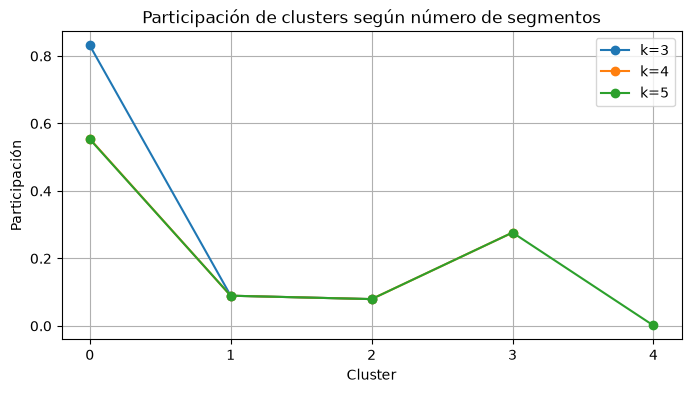

In [104]:
# Gráfico simple para comparar la participación de cada cluster según el valor de k.
# Ayuda a ver si alguna solución genera clusters demasiado pequeños o fragmentados.

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))

for k in [3, 4, 5]:
    temp = comparacion_k[comparacion_k["k"] == k]
    plt.plot(
        temp["Cluster"].astype(str),
        temp["Participacion"],
        marker="o",
        label=f"k={k}"
    )

plt.xlabel("Cluster")
plt.ylabel("Participación")
plt.title("Participación de clusters según número de segmentos")
plt.legend()
plt.grid(True)
plt.show()

In [105]:
x = 0.1
y = 0.2

print(x+y)

0.30000000000000004
